In [24]:
import requests
import os
import time

from numba import njit, prange
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
def random_matrix(N, RANGE):
    """Genera una matriz aleatoria de tamaño NxN con valores en el rango [-RANGE, RANGE]."""
    return np.random.uniform(-RANGE, RANGE, (N, N))


@njit(parallel=True)
def matmul_numba(A, B, C, N):
    # Inicializar C a cero dentro del kernel para evitar dependencias externas
    for i in range(N):
        for j in range(N):
            C[i, j] = 0.0
            
    # Paralelismo de datos en el loop externo
    for i in prange(N):
        for k in range(N):
            for j in range(N):
                C[i, j] += A[i, k] * B[k, j]

In [ ]:
A = random_matrix(2048, 10)
B = random_matrix(2048, 10)
C = np.zeros((2048, 2048), dtype=np.float64)
N = 2048

print("Ejecutando warm-up (compilación JIT)...")
matmul_numba(A, B, C, N)
    
threads_list = [1, 2, 4, 8]
results = []

filename = "resultados-py-alg-1.txt"

print("=== Numba: Paralelismo de Datos con Numba ===\n")
print(f"Tamaño de matriz: N = {N}")

# Abrir el archivo para escritura
with open(filename, 'w') as f:
    # Escribir encabezado idéntico al estilo C++
    f.write("Algoritmo: Multiplicación de Matrices con Numba\n")
    f.write(f"Tamaño de Matriz (N): {N}\n")
    f.write("Threads\tTiempo (ms)\tSpeedup (vs P=1)\tEficiencia (vs P=1)\n")
    f.write("-" * 60 + "\n")

    time_p1 = 0.0 # Variable para guardar el tiempo del caso base (1 thread)

    for p in threads_list:
        C[:] = 0.0 
        
        # Nota: En versiones recientes de Numba, set_num_threads() es preferible
        # si está disponible, pero NUMBA_NUM_THREADS sigue funcionando en muchos casos.
        os.environ['NUMBA_NUM_THREADS'] = str(p)
        
        start = time.perf_counter()
        matmul_numba(A, B, C, N)
        end = time.perf_counter()
        
        elapsed_ms = (end - start) * 1000
        
        # Guardar tiempo de referencia si es p=1
        if p == 1:
            time_p1 = elapsed_ms
            
        # Calcular Speedup y Eficiencia
        # Evitamos división por cero si time_p1 fuera 0 (improbable)
        speedup = time_p1 / elapsed_ms if elapsed_ms > 0 else 0
        efficiency = speedup / p if p > 0 else 0

        # Imprimir en consola con formato alineado
        print(f"Threads: {p:<5} Tiempo: {elapsed_ms:.2f} ms\tSpeedup: {speedup:.2f}\tEficiencia: {efficiency:.2f}")
        
        # Escribir en el archivo separado por tabuladores
        f.write(f"{p}\t{elapsed_ms:.2f}\t{speedup:.2f}\t{efficiency:.2f}\n")

print(f"\nResultados guardados en {filename}")

Ejecutando warm-up (compilación JIT)...
=== Algoritmo 3: Paralelismo de Datos con Numba ===

Tamaño de matriz: N = 2048
Threads: 1     Tiempo: 2365.83 ms	Speedup: 1.00	Eficiencia: 1.00
Threads: 2     Tiempo: 2158.36 ms	Speedup: 1.10	Eficiencia: 0.55
Threads: 4     Tiempo: 2276.43 ms	Speedup: 1.04	Eficiencia: 0.26
Threads: 8     Tiempo: 2378.29 ms	Speedup: 0.99	Eficiencia: 0.12

Resultados guardados en resultados-py-alg-1.txt


In [11]:
def leer_resultados_tarea(ruta_archivo, nombre_alg):
    with open(ruta_archivo, 'r', encoding='utf-8') as f:
        lines = f.readlines()
    
    data = []
    header_found = False
    
    for line in lines:
        line = line.strip()
        # Ignorar líneas vacías o separadores
        if not line or line.startswith('---'):
            continue
            
        # Detectar el encabezado basado en las palabras clave
        if 'Threads' in line and 'Tiempo' in line:
            header_found = True
            continue
            
        if header_found:
            # Dividir por espacios múltiples o tabulaciones
            parts = line.split()
            if len(parts) >= 3: # Asegurar que hay datos mínimos
                try:
                    threads = int(parts[0])
                    tiempo = float(parts[1])
                    
                    # Dependiendo del archivo, las columnas de speedup/eficiencia varían
                    # Alg 1 (OpenMP Data Parallelism) tiene más columnas en tu ejemplo
                    # Alg 2 y Py-Alg-1 tienen formato: Threads Tiempo Speedup Eficiencia
                    
                    if len(parts) == 4:
                        speedup = float(parts[2])
                        eficiencia = float(parts[3])
                        speedup_vs_seq = None
                        eficiencia_vs_seq = None
                    elif len(parts) >= 6: 
                        # Caso específico de resultados-alg1.txt que tiene más métricas
                        # Threads Tiempo(ms) Speedup(vs Seq) Eficiencia(vs Seq) Speedup(vs P=1) Eficiencia(vs P=1)
                        speedup_vs_seq = float(parts[2])
                        eficiencia_vs_seq = float(parts[3])
                        speedup = float(parts[4])
                        eficiencia = float(parts[5])
                    else:
                        continue
                        
                    data.append({
                        'Algoritmo': nombre_alg,
                        'Threads': threads,
                        'Tiempo_ms': tiempo,
                        'Speedup': speedup,
                        'Eficiencia': eficiencia,
                        'Speedup_vs_Seq': speedup_vs_seq,
                        'Eficiencia_vs_Seq': eficiencia_vs_seq
                    })
                except ValueError:
                    continue
                    
    return pd.DataFrame(data)

In [28]:
resultados_path = ["resultados-alg-2.txt", "resultados-alg1.txt", "resultados-py-alg-1.txt"]
resultados = {}
for path in resultados_path:
    if not os.path.exists(path):
        print(f"Archivo {path} no encontrado. Asegúrate de ejecutar los algoritmos primero.")
        exit(1)
    else:
        resultados[path] = leer_resultados_tarea(path, path.split('-')[1].split('.')[0])

df_total = pd.concat(resultados.values(), ignore_index=True)[["Algoritmo", "Threads", "Tiempo_ms", "Speedup", "Eficiencia"]]
## Reemplazamos "alg" con "alg2"
df_total["Algoritmo"] = df_total["Algoritmo"].replace({"alg1": "OpenMP", "alg": "Dividir para conquistar", "py": "Numba"})

## Ordenamos por threads
df_total = df_total.sort_values(by=["Algoritmo", "Threads"]).reset_index(drop=True)
# 3. Mostrar el resultado
print("Dataset Completo:")
df_total

Dataset Completo:


,Algoritmo,Threads,Tiempo_ms,Speedup,Eficiencia
0,Dividir para conquistar,1,6977.08,1.00000,1.000000
1,Dividir para conquistar,2,6068.60,1.14970,0.574851
2,Dividir para conquistar,4,6562.04,1.06325,0.265812
3,Dividir para conquistar,8,6383.24,1.09303,0.136629
4,Numba,1,2365.83,1.00000,1.000000
5,Numba,2,2158.36,1.10000,0.550000
6,Numba,4,2276.43,1.04000,0.260000
7,Numba,8,2378.29,0.99000,0.120000
8,OpenMP,1,4905.43,1.00000,1.000000
9,OpenMP,2,4625.44,1.06053,0.530267


In [ ]:
def plot_comparacion_paralela(df, nombre_figura="nombre.jpg"):
    # Configuración de estilo
    
    sns.set_style("whitegrid")
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    # Paleta de colores consistente
    palette = {"OpenMP": "#1f77b4", "Dividir para conquistar": "#ff7f0e", "Numba": "#2ca02c"}
    markers = {"OpenMP": "o", "Dividir para conquistar": "s", "Numba": "^"}

    # --- Gráfico 1: Tiempo de Ejecución ---
    sns.lineplot(data=df, x="Threads", y="Tiempo_ms", hue="Algoritmo", 
                 style="Algoritmo", markers=markers, dashes=False, 
                 palette=palette, ax=axes[0], linewidth=2)
    axes[0].set_title("Tiempo de Ejecución (ms)", fontsize=14)
    axes[0].set_xlabel("Número de Threads")
    axes[0].set_ylabel("Tiempo (ms)")
    axes[0].legend(title="Algoritmo")

    # --- Gráfico 2: Speedup ---
    sns.lineplot(data=df, x="Threads", y="Speedup", hue="Algoritmo", 
                 style="Algoritmo", markers=markers, dashes=False, 
                 palette=palette, ax=axes[1], linewidth=2)
    
    # Línea ideal de Speedup (S = p)
    threads_unicos = sorted(df['Threads'].unique())
    axes[1].plot(threads_unicos, threads_unicos, 'k--', label='Ideal (Lineal)', alpha=0.5)
    
    axes[1].set_title("Speedup S(p)", fontsize=14)
    axes[1].set_xlabel("Número de Threads")
    axes[1].set_ylabel("Speedup")
    axes[1].legend(title="Algoritmo")

    # --- Gráfico 3: Eficiencia ---
    sns.lineplot(data=df, x="Threads", y="Eficiencia", hue="Algoritmo", 
                 style="Algoritmo", markers=markers, dashes=False, 
                 palette=palette, ax=axes[2], linewidth=2)
    
    # Línea ideal de Eficiencia (E = 1)
    axes[2].axhline(y=1.0, color='k', linestyle='--', alpha=0.5, label='Ideal (100%)')
    
    axes[2].set_title("Eficiencia E(p)", fontsize=14)
    axes[2].set_xlabel("Número de Threads")
    axes[2].set_ylabel("Eficiencia")
    axes[2].legend(title="Algoritmo")

    # Ajuste final del layout
    plt.tight_layout()
    plt.savefig(nombre_figura, dpi=300, bbox_inches='tight')
    plt.show()


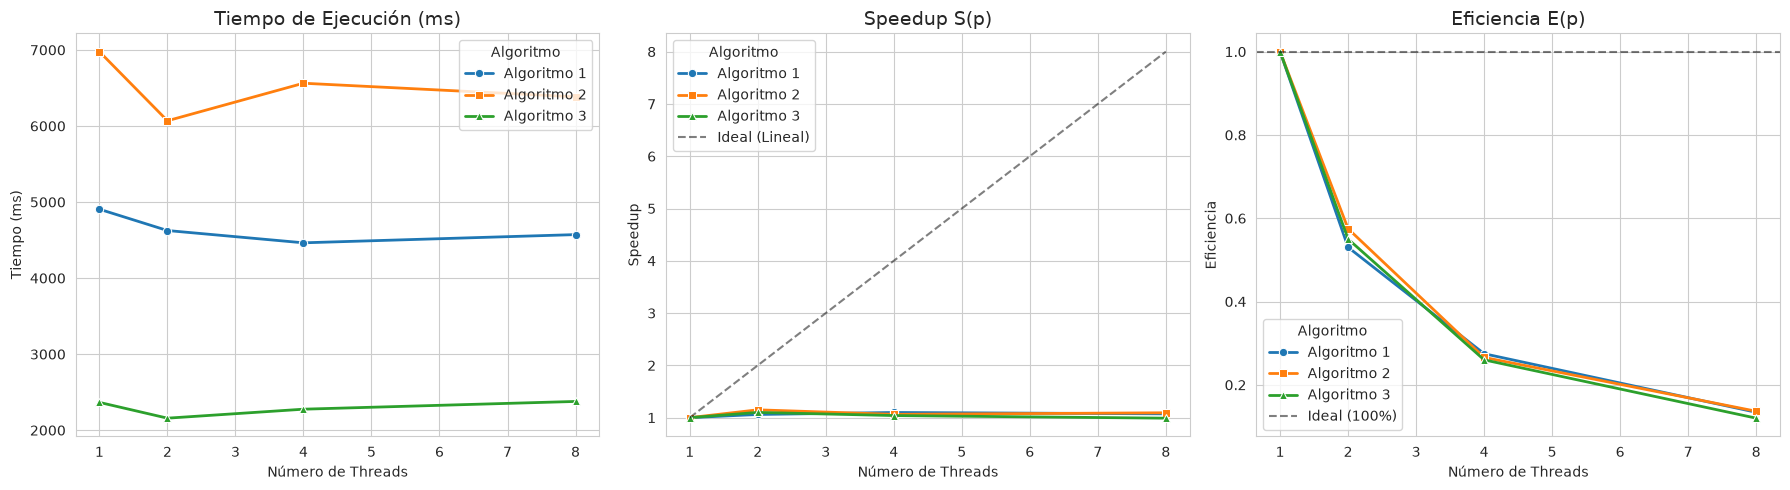

In [ ]:
plot_comparacion_paralela(df_total, nombre_figura="comparacion_algoritmo.png")